# Exploratory Data Analysis of Health Measurements

This notebook analyzes the existing `health_measurements_100_observations.xlsx` workbook without changing it. The observations are synthetic, not real patient data; the analysis is descriptive and cannot support medical conclusions.

The analysis checks the expected 100 observations and four measurements, reviews data quality, calculates descriptive statistics, and visualizes distributions and relationships. Plausibility thresholds below are screening flags only, not clinical criteria.

### How to read and run this notebook

Read the short Markdown guide before each code cell, then run the notebook from top to bottom so each step has the variables it needs. Code cells perform the analysis; the Markdown cells explain the goal, key Python operations, and how to read the output. Tables, charts, and the final written summary are calculated from the workbook when the cells run.

## 1. Import libraries and locate the workbook

### Reading this step

The imports give us tools for tables and calculations (`pandas`, `numpy`), charts (`matplotlib`), and statistical plotting (`seaborn`). `Path` handles file locations. The code checks the notebook's current folder and its parent for the existing Excel workbook; if it cannot find it, it raises a clear error listing the paths checked rather than silently using another file. The final print confirms which workbook will be read.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

WORKBOOK_NAME = "health_measurements_100_observations.xlsx"
workbook_candidates = [Path.cwd() / WORKBOOK_NAME, Path.cwd().parent / WORKBOOK_NAME]
workbook_path = next((path for path in workbook_candidates if path.is_file()), None)

if workbook_path is None:
    searched_paths = "\n".join(str(path.resolve()) for path in workbook_candidates)
    raise FileNotFoundError(
        f"Could not find {WORKBOOK_NAME}. Checked these paths:\n{searched_paths}"
    )

print(f"Loading workbook: {workbook_path.resolve()}")

Loading workbook: C:\Users\David Dagbanja\Desktop\New folder\health_measurements_100_observations.xlsx


## 2. Load the data and inspect its structure

### Reading this step

`pd.read_excel()` reads the workbook into `df`; it does not edit the Excel file. `head()` and `tail()` show the first and last five records so you can inspect examples. The row and column counts, shape, column names, and data types tell us what was actually loaded. The checks compare the observed shape and column names with the requested 100 rows and four named measurements, and report discrepancies instead of assuming the file matches.

In [2]:
df = pd.read_excel(workbook_path)

expected_columns = ["Age", "Height_cm", "Weight_kg", "Pulse_rate_bpm"]
expected_shape = (100, 4)

print("First five observations:")
display(df.head())

print("Last five observations:")
display(df.tail())

print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print(f"Shape: {df.shape}")
print("Column names:", list(df.columns))
print("Data types:")
display(df.dtypes.rename("data_type").to_frame())

if df.shape != expected_shape:
    print(f"DISCREPANCY: expected {expected_shape[0]} observations and "
          f"{expected_shape[1]} columns, but found {df.shape}.")
else:
    print("Shape check passed: 100 observations and four columns.")

if list(df.columns) != expected_columns:
    print("DISCREPANCY: expected columns in this order:", expected_columns)
    print("Actual columns:", list(df.columns))
else:
    print("Column-name and order check passed.")

First five observations:


,Age,Height_cm,Weight_kg,Pulse_rate_bpm
0,60,168.6,70.9,67
1,32,146.3,78.4,88
2,39,153.2,76.2,55
3,49,172.6,70.8,89
4,53,170.9,93.2,75


Last five observations:


,Age,Height_cm,Weight_kg,Pulse_rate_bpm
95,46,171.4,72.9,89
96,22,159.2,59.0,97
97,39,167.7,78.7,78
98,64,160.7,58.1,77
99,65,172.8,71.6,75


Number of rows: 100
Number of columns: 4
Shape: (100, 4)
Column names: ['Age', 'Height_cm', 'Weight_kg', 'Pulse_rate_bpm']
Data types:


,data_type
Age,int64
Height_cm,float64
Weight_kg,float64
Pulse_rate_bpm,int64


Shape check passed: 100 observations and four columns.
Column-name and order check passed.


## 3. Data quality checks

### Reading this step

The missing-value table counts blank cells per column; `duplicated()` counts repeated full rows. Each expected measurement is also checked for non-numeric entries. The broad value bounds flag records for human review, not as clinical rules. `numeric_data` is a separate converted view used by later calculations, so the source DataFrame `df` remains unchanged. If something is flagged, verify it against the source before considering a correction; this notebook does not silently remove or replace values.

In [3]:
print("Missing values by column:")
missing_by_column = df.isna().sum().rename("missing_count").to_frame()
display(missing_by_column)

duplicate_count = int(df.duplicated().sum())
print(f"Duplicate rows: {duplicate_count}")

available_measurements = [column for column in expected_columns if column in df.columns]
numeric_data = pd.DataFrame(index=df.index)
non_numeric_counts = {}

for column in available_measurements:
    converted = pd.to_numeric(df[column], errors="coerce")
    non_numeric_counts[column] = int((df[column].notna() & converted.isna()).sum())
    numeric_data[column] = converted

print("Non-numeric values in expected measurement columns:")
display(pd.Series(non_numeric_counts, name="non_numeric_count").to_frame())

plausibility_bounds = {
    "Age": (0, 120, "years; values must be > 0 and <= 120"),
    "Height_cm": (0, 250, "cm; values must be > 0 and <= 250"),
    "Weight_kg": (0, 500, "kg; values must be > 0 and <= 500"),
    "Pulse_rate_bpm": (0, 250, "bpm; values must be > 0 and <= 250"),
}

plausibility_rows = []
for column, (lower_bound, upper_bound, screening_rule) in plausibility_bounds.items():
    if column not in numeric_data.columns:
        continue
    invalid_mask = numeric_data[column].notna() & (
        (numeric_data[column] <= lower_bound) | (numeric_data[column] > upper_bound)
    )
    plausibility_rows.append({
        "column": column,
        "flagged_count": int(invalid_mask.sum()),
        "flagged_values": numeric_data.loc[invalid_mask, column].tolist(),
        "screening_rule": screening_rule,
    })

plausibility_results = pd.DataFrame(plausibility_rows).set_index("column")
print("Plausibility screening flags (not clinical criteria):")
display(plausibility_results)

if duplicate_count or missing_by_column["missing_count"].sum() or sum(non_numeric_counts.values()) or (
    not plausibility_results.empty and plausibility_results["flagged_count"].sum()
):
    print("Review the flagged records against the source before deciding whether to correct them. "
          "No values have been changed or removed.")
else:
    print("No missing values, duplicate rows, non-numeric measurement values, or screening flags were detected.")

print("\nOriginal column data types and numeric suitability:")
for column in expected_columns:
    if column not in df.columns:
        print(f"- {column}: column is missing.")
    elif pd.api.types.is_numeric_dtype(df[column]):
        print(f"- {column}: numeric dtype ({df[column].dtype}).")
    else:
        print(f"- {column}: non-numeric dtype ({df[column].dtype}); inspect values and consider "
              "a validated numeric conversion if appropriate. The source data was not changed.")

Missing values by column:


,missing_count
Age,0
Height_cm,0
Weight_kg,0
Pulse_rate_bpm,0


Duplicate rows: 0
Non-numeric values in expected measurement columns:


,non_numeric_count
Age,0
Height_cm,0
Weight_kg,0
Pulse_rate_bpm,0


Plausibility screening flags (not clinical criteria):


,flagged_count,flagged_values,screening_rule
column,,,
Age,0,[],years; values must be > 0 and <= 120
Height_cm,0,[],cm; values must be > 0 and <= 250
Weight_kg,0,[],kg; values must be > 0 and <= 500
Pulse_rate_bpm,0,[],bpm; values must be > 0 and <= 250


No missing values, duplicate rows, non-numeric measurement values, or screening flags were detected.



Original column data types and numeric suitability:
- Age: numeric dtype (int64).
- Height_cm: numeric dtype (float64).
- Weight_kg: numeric dtype (float64).
- Pulse_rate_bpm: numeric dtype (int64).


## 4. Descriptive statistics

### Reading this step

`describe()` reports count, mean, standard deviation, quartiles, and extremes. The labelled table adds median and mode (the most frequent value; there can be more than one), plus range (`maximum - minimum`). Variance measures spread in squared units, while standard deviation is in the measurement's original units. `ddof=1` requests sample variance and sample standard deviation. These values are calculated from the numeric observations actually loaded; `NaN` means a statistic could not be calculated.

In [4]:
print("Pandas describe() for available numeric measurements:")
if available_measurements:
    display(numeric_data[available_measurements].describe().T)
else:
    print("No expected measurement columns are available for numeric summaries.")

units = {
    "Age": "years",
    "Height_cm": "cm",
    "Weight_kg": "kg",
    "Pulse_rate_bpm": "bpm",
}
statistics_rows = []

for column in available_measurements:
    values = numeric_data[column].dropna()
    mode_values = values.mode().tolist()
    statistics_rows.append({
        "measurement": f"{column} ({units[column]})",
        "count": int(values.count()),
        "mean": values.mean(),
        "median": values.median(),
        "mode": ", ".join(f"{value:g}" for value in mode_values) if mode_values else "No mode",
        "minimum": values.min(),
        "maximum": values.max(),
        "range": values.max() - values.min(),
        "sample_variance (squared units)": values.var(ddof=1),
        "sample_standard_deviation": values.std(ddof=1),
    })

statistics_table = pd.DataFrame(statistics_rows).set_index("measurement")
display(statistics_table.round(3))

Pandas describe() for available numeric measurements:


,count,mean,std,min,25%,50%,75%,max
Age,100.0,44.930,15.191209,18.0,32.000,44.0,60.00,70.0
Height_cm,100.0,168.399,8.754952,146.3,162.750,168.6,174.40,186.5
Weight_kg,100.0,72.922,12.712227,42.0,64.175,71.5,81.05,109.3
Pulse_rate_bpm,100.0,78.030,13.727106,55.0,65.000,77.5,89.25,100.0


,count,mean,median,mode,minimum,maximum,range,sample_variance (squared units),sample_standard_deviation
measurement,,,,,,,,,
Age (years),100,44.930,44.0,"32, 39, 60, 64",18.0,70.0,52.0,230.773,15.191
Height_cm (cm),100,168.399,168.6,174.7,146.3,186.5,40.2,76.649,8.755
Weight_kg (kg),100,72.922,71.5,70.9,42.0,109.3,67.3,161.601,12.712
Pulse_rate_bpm (bpm),100,78.030,77.5,75,55.0,100.0,45.0,188.433,13.727


## 5. Distributions

### Reading this step

A histogram groups numeric observations into value intervals (bins). The horizontal axis shows the measurement and the vertical axis counts observations in each interval. Look at the overall shape, concentration, spread, gaps, and possible isolated bars; a histogram is a descriptive view, not a statistical test. Each variable gets its own labelled figure. Missing or non-numeric values are skipped for plotting, not deleted from `df`.

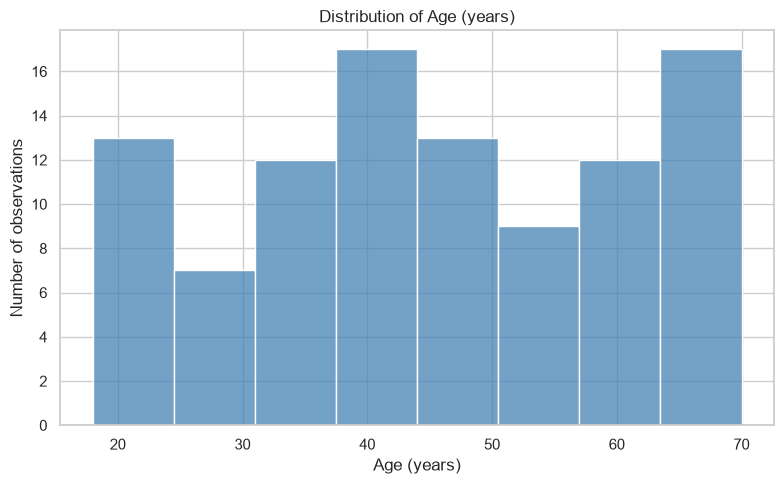

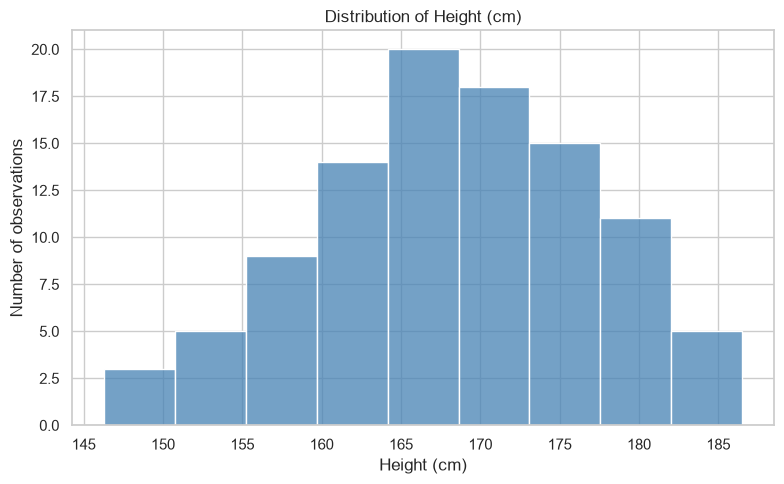

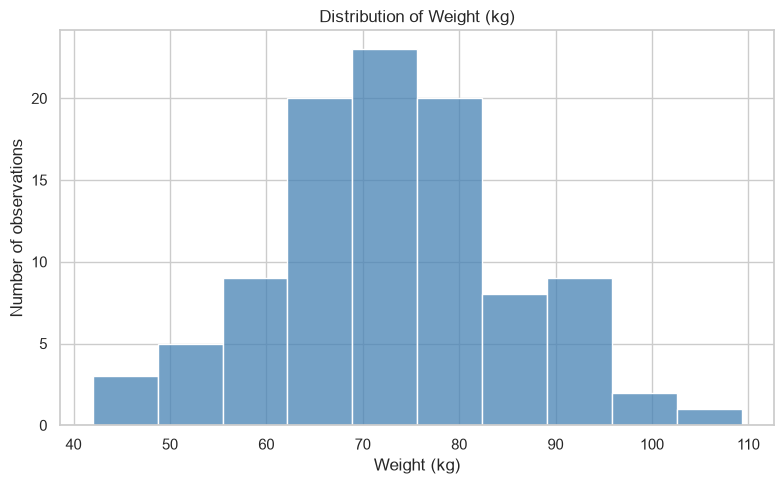

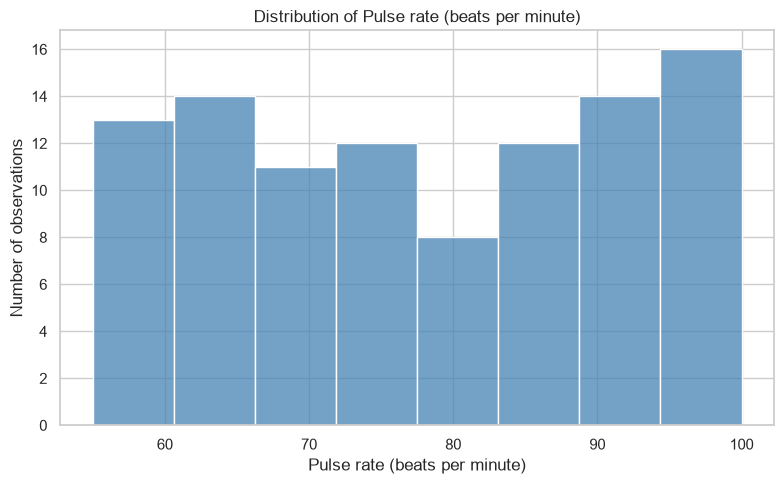

In [5]:
measurement_labels = {
    "Age": "Age (years)",
    "Height_cm": "Height (cm)",
    "Weight_kg": "Weight (kg)",
    "Pulse_rate_bpm": "Pulse rate (beats per minute)",
}

for column in expected_columns:
    if column not in numeric_data.columns:
        print(f"Skipping histogram for {column}: column is unavailable.")
        continue
    values = numeric_data[column].dropna()
    if values.empty:
        print(f"Skipping histogram for {column}: no numeric observations are available.")
        continue
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(values, bins="auto", kde=False, ax=ax, color="steelblue")
    ax.set(title=f"Distribution of {measurement_labels[column]}",
           xlabel=measurement_labels[column], ylabel="Number of observations")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 6. Relationships between measurements

### Reading this step

Each point is one record, with age or height on the horizontal axis and weight on the vertical axis. A general upward or downward pattern can suggest an association; a diffuse cloud suggests little obvious linear pattern. Outlying points may be worth checking against the source. The plot only describes these paired observations and cannot show that one measurement causes another.

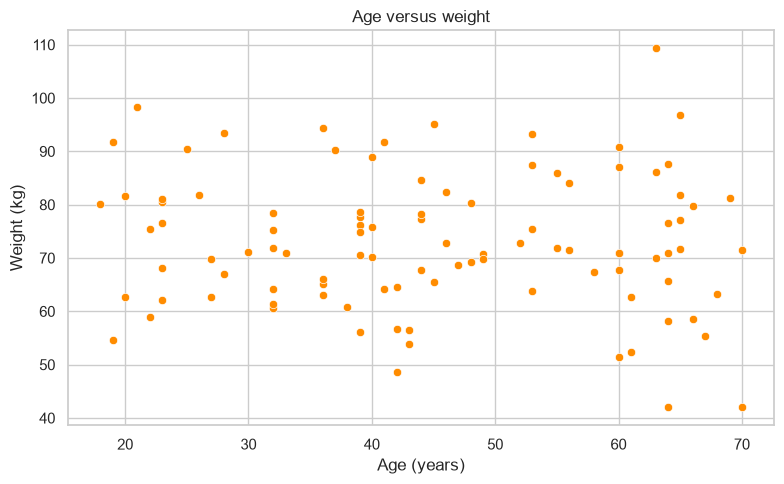

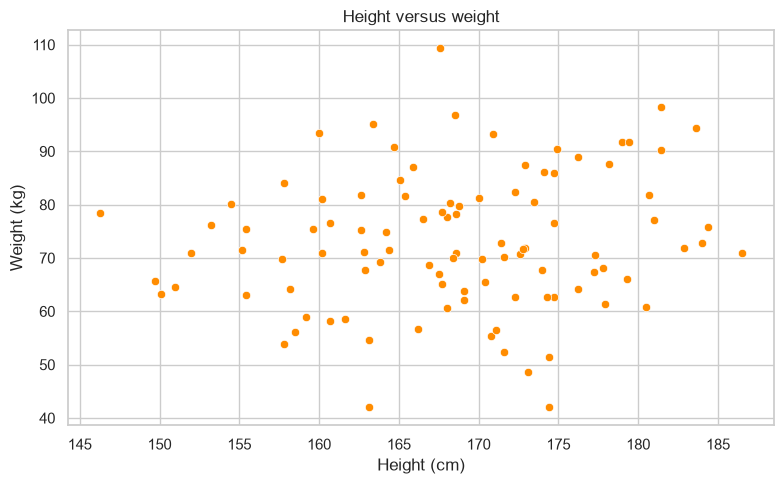

In [6]:
scatter_pairs = [
    ("Age", "Weight_kg", "Age versus weight", "Age (years)", "Weight (kg)"),
    ("Height_cm", "Weight_kg", "Height versus weight", "Height (cm)", "Weight (kg)"),
]

for x_column, y_column, title, x_label, y_label in scatter_pairs:
    if x_column not in numeric_data.columns or y_column not in numeric_data.columns:
        print(f"Skipping {title}: one or both columns are unavailable.")
        continue
    plot_data = numeric_data[[x_column, y_column]].dropna()
    if plot_data.empty:
        print(f"Skipping {title}: no complete numeric pairs are available.")
        continue
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.scatterplot(data=plot_data, x=x_column, y=y_column, ax=ax, color="darkorange")
    ax.set(title=title, xlabel=x_label, ylabel=y_label)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 7. Correlation analysis

### Reading this step

The correlation matrix displays Pearson's *r* for each pair of available numeric measurements. Values are between -1 and +1: values nearer +1 represent stronger positive linear association, values nearer -1 stronger negative linear association, and values near 0 little linear association. The diagonal is 1 because each variable is perfectly correlated with itself. The heatmap visualizes the same matrix. The code compares unique variable pairs (excluding the diagonal) to identify the strongest positive and negative values from this dataset; neither correlation nor a heatmap establishes causation.

Correlation matrix:


,Age,Height_cm,Weight_kg,Pulse_rate_bpm
Age,1.000,-0.043,-0.067,-0.074
Height_cm,-0.043,1.000,0.148,0.140
Weight_kg,-0.067,0.148,1.000,-0.103
Pulse_rate_bpm,-0.074,0.140,-0.103,1.000


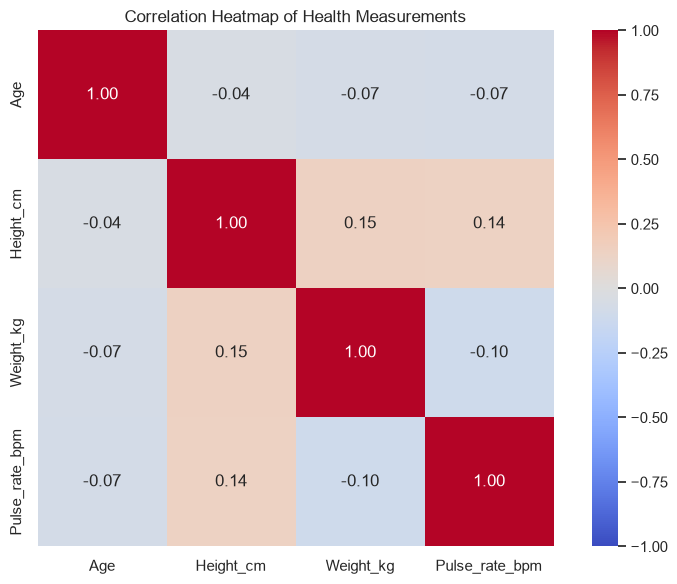

Strongest positive correlation: Height_cm and Weight_kg (r = 0.148)
Strongest negative correlation: Weight_kg and Pulse_rate_bpm (r = -0.103)


In [7]:
correlation_matrix = numeric_data[available_measurements].corr() if available_measurements else pd.DataFrame()

print("Correlation matrix:")
display(correlation_matrix.round(3))

if not correlation_matrix.empty:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title("Correlation Heatmap of Health Measurements")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
else:
    print("Heatmap unavailable: no expected numeric columns are present.")

pair_correlations = []
if len(correlation_matrix.columns) >= 2:
    for row_index, first_column in enumerate(correlation_matrix.columns):
        for second_column in correlation_matrix.columns[row_index + 1:]:
            value = correlation_matrix.loc[first_column, second_column]
            if pd.notna(value):
                pair_correlations.append((first_column, second_column, float(value)))

positive_correlations = [pair for pair in pair_correlations if pair[2] > 0]
negative_correlations = [pair for pair in pair_correlations if pair[2] < 0]
strongest_positive = max(positive_correlations, key=lambda pair: pair[2]) if positive_correlations else None
strongest_negative = min(negative_correlations, key=lambda pair: pair[2]) if negative_correlations else None

def describe_correlation(pair):
    if pair is None:
        return "No finite correlation of this sign was found among the available pairs."
    return f"{pair[0]} and {pair[1]} (r = {pair[2]:.3f})"

print("Strongest positive correlation:", describe_correlation(strongest_positive))
print("Strongest negative correlation:", describe_correlation(strongest_negative))

## 8. Interpretation and conclusion

### Reading this step

The final code cell builds a Markdown report from the statistics, data-quality checks, shape, and correlations calculated earlier. Distribution descriptions use sample skewness: a value near zero is relatively symmetric, positive skew indicates a longer right tail, and negative skew indicates a longer left tail. This is only a compact description, not a formal test. Re-run the notebook from the top after changing the source workbook if you want the tables, charts, and conclusion refreshed. The limitations matter: these are synthetic observations, not patient records, so the results cannot be used to make medical claims.

In [8]:
from IPython.display import Markdown, display

def format_statistic(value, digits=2):
    return "not available" if pd.isna(value) else f"{value:.{digits}f}"

distribution_findings = []
for column in available_measurements:
    values = numeric_data[column].dropna()
    if len(values) < 3 or values.nunique() < 2:
        shape_description = "shape cannot be meaningfully described from these values"
    else:
        skewness = values.skew()
        if pd.isna(skewness):
            shape_description = "skewness is unavailable"
        elif abs(skewness) < 0.5:
            shape_description = f"approximately symmetric by skewness (skew = {skewness:.2f})"
        elif skewness > 0:
            shape_description = f"right-skewed by skewness (skew = {skewness:.2f})"
        else:
            shape_description = f"left-skewed by skewness (skew = {skewness:.2f})"
    distribution_findings.append(f"- **{column}**: {shape_description}.")

statistic_findings = []
for _, row in statistics_table.iterrows():
    statistic_findings.append(
        f"- **{row.name}**: mean {format_statistic(row['mean'])}, "
        f"median {format_statistic(row['median'])}, range {format_statistic(row['range'])}."
    )

missing_total = int(df.isna().sum().sum())
non_numeric_total = sum(non_numeric_counts.values())
flagged_total = int(plausibility_results["flagged_count"].sum()) if not plausibility_results.empty else 0
quality_summary = (
    f"There are **{missing_total} missing cells**, **{duplicate_count} duplicate rows**, "
    f"**{non_numeric_total} non-numeric values** across expected measurements, and "
    f"**{flagged_total} values flagged** by the broad screening bounds. "
    "These are observations for review, not automatically corrected errors."
)

schema_summary = (
    "The dataset matches the expected 100 observations and four columns."
    if df.shape == expected_shape and list(df.columns) == expected_columns
    else f"The dataset does not match the expected shape/schema: actual shape is {df.shape}, "
         f"with columns {list(df.columns)}."
)

correlation_summary = (
    f"The strongest positive pair is {describe_correlation(strongest_positive)} "
    f"The strongest negative pair is {describe_correlation(strongest_negative)}"
)

conclusion = f"""
### Findings from the loaded workbook

- **Structure:** {schema_summary}
- **Descriptive statistics:**
{chr(10).join(statistic_findings) if statistic_findings else '- No expected numeric measurement columns were available for summary statistics.'}
- **Distributions:**
{chr(10).join(distribution_findings) if distribution_findings else '- No expected numeric measurement columns were available for distribution descriptions.'}
- **Data quality:** {quality_summary}
- **Relationships:** {correlation_summary} These are descriptive associations, not evidence of causation.

### Limitations and conclusion

This workbook contains **synthetic observations, not real patient data**. The dataset is limited to 100 observations and four measurements, and its synthetic nature and size limit generalizability. Summary statistics and correlations describe only these observations; they cannot be used to draw medical conclusions about real patients, diagnose conditions, or infer causal relationships. Any flagged records should be checked against an authoritative source before a correction is considered. The original workbook and `df` have not been modified by this analysis.
"""

display(Markdown(conclusion))


### Findings from the loaded workbook

- **Structure:** The dataset matches the expected 100 observations and four columns.
- **Descriptive statistics:**
- **Age (years)**: mean 44.93, median 44.00, range 52.00.
- **Height_cm (cm)**: mean 168.40, median 168.60, range 40.20.
- **Weight_kg (kg)**: mean 72.92, median 71.50, range 67.30.
- **Pulse_rate_bpm (bpm)**: mean 78.03, median 77.50, range 45.00.
- **Distributions:**
- **Age**: approximately symmetric by skewness (skew = -0.05).
- **Height_cm**: approximately symmetric by skewness (skew = -0.24).
- **Weight_kg**: approximately symmetric by skewness (skew = 0.12).
- **Pulse_rate_bpm**: approximately symmetric by skewness (skew = -0.02).
- **Data quality:** There are **0 missing cells**, **0 duplicate rows**, **0 non-numeric values** across expected measurements, and **0 values flagged** by the broad screening bounds. These are observations for review, not automatically corrected errors.
- **Relationships:** The strongest positive pair is Height_cm and Weight_kg (r = 0.148) The strongest negative pair is Weight_kg and Pulse_rate_bpm (r = -0.103) These are descriptive associations, not evidence of causation.

### Limitations and conclusion

This workbook contains **synthetic observations, not real patient data**. The dataset is limited to 100 observations and four measurements, and its synthetic nature and size limit generalizability. Summary statistics and correlations describe only these observations; they cannot be used to draw medical conclusions about real patients, diagnose conditions, or infer causal relationships. Any flagged records should be checked against an authoritative source before a correction is considered. The original workbook and `df` have not been modified by this analysis.
